# 03 · Visualizaciones

**Fase CRISP-DM:** *Data Preparation* (visualizaciones). Con los datos limpios, los gráficos que responden a las preguntas de negocio de `README.md`, pulidos y guardados en `figures/`. La exploración rápida está en `01_exploracion.ipynb` y no se repite aquí.

- **Entrada:** `data/processed/empresas_limpias.parquet`
- **Salida:** `figures/fig01_*.png` a `figures/fig05_*.png`

In [1]:
# Permite importar src/ desde la carpeta notebooks/
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src import estilo, utils

estilo.apply_style()

df = utils.load_clean()
# Dificultad financiera: pérdidas netas o patrimonio negativo
distress = utils.is_distressed(df["net_income"], df["total_equity"])
print(df.shape)

(47115, 14)


## P1 · ¿Qué tan grandes son las empresas y qué tan desigual es su tamaño?

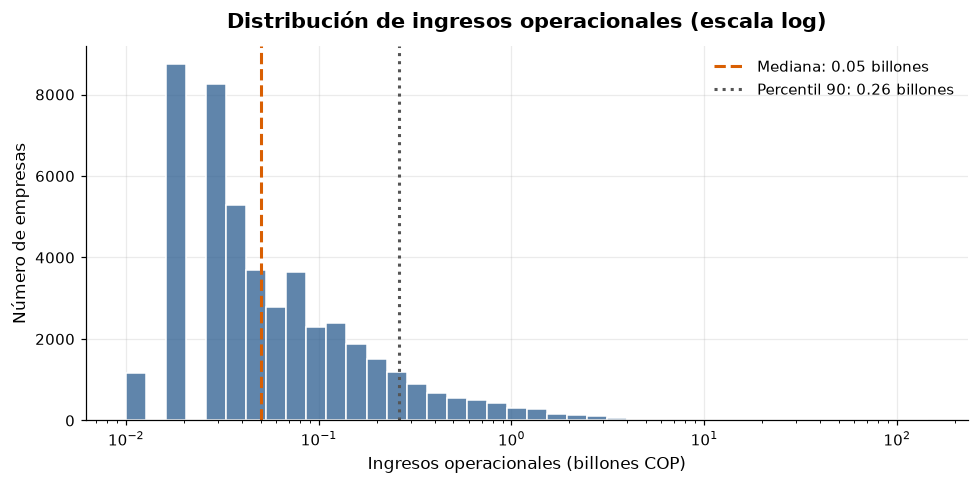

In [2]:
revenue = df["operating_revenue"]
median_rev = revenue.median()
p90_rev = revenue.quantile(0.9)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(revenue, bins=40, log_scale=True, color=estilo.MAIN, edgecolor="white", ax=ax)
ax.axvline(median_rev, color=estilo.ALERT, linestyle="--", linewidth=2, label=f"Mediana: {median_rev:.2f} billones")
ax.axvline(p90_rev, color=estilo.NEUTRAL, linestyle=":", linewidth=2, label=f"Percentil 90: {p90_rev:.2f} billones")
ax.set_title("Distribución de ingresos operacionales (escala log)")
ax.set_xlabel("Ingresos operacionales (billones COP)")
ax.set_ylabel("Número de empresas")
ax.legend()
plt.tight_layout()
estilo.save_figure(fig, "fig01_distribucion_ingresos.png")
plt.show()

## P2 · ¿Dónde están las grandes empresas?

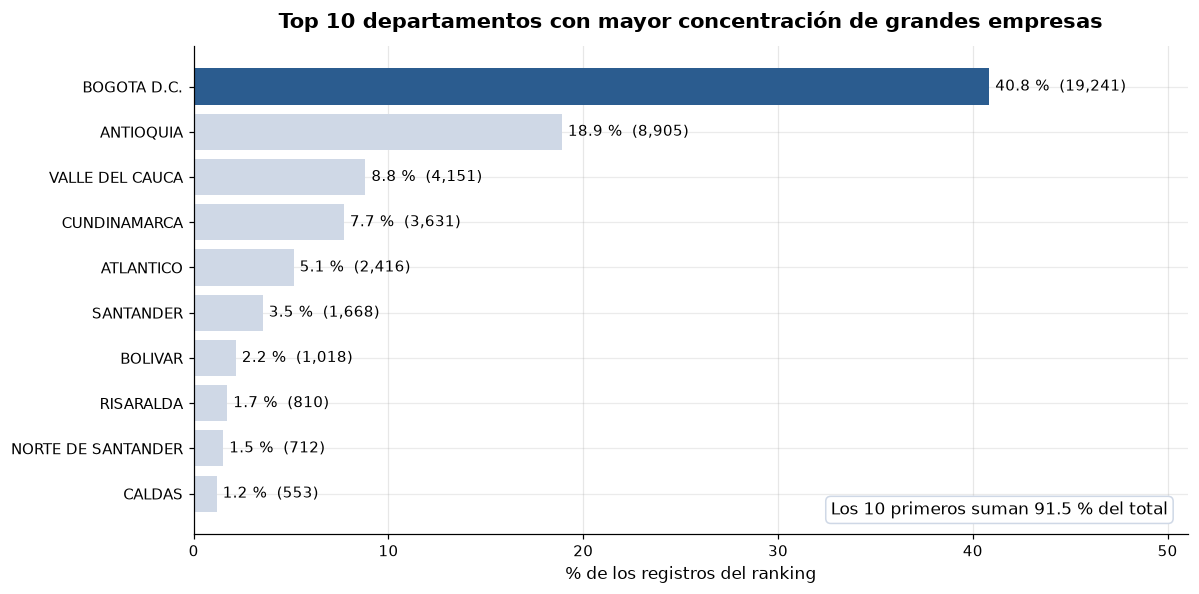

In [3]:
dept_counts = df["department"].value_counts()
top_counts = dept_counts.head(10).sort_values()
top_pcts = top_counts / dept_counts.sum() * 100

fig, ax = plt.subplots(figsize=(11, 5.5))
estilo.labeled_barh(
    ax, top_pcts,
    labels=estilo.pct_count_labels(top_pcts, top_counts),
    colors=estilo.highlight_last(len(top_pcts)),
    room=1.25,
)
ax.set_title("Top 10 departamentos con mayor concentración de grandes empresas")
ax.set_xlabel("% de los registros del ranking")
ax.text(
    0.98, 0.04, f"Los 10 primeros suman {top_pcts.sum():.1f} % del total",
    transform=ax.transAxes, ha="right", fontsize=11,
    bbox=dict(boxstyle="round", facecolor="white", edgecolor=estilo.MUTED),
)
plt.tight_layout()
estilo.save_figure(fig, "fig02_top10_departamentos.png")
plt.show()

## P3 · ¿Qué sectores tienen más empresas en dificultad?

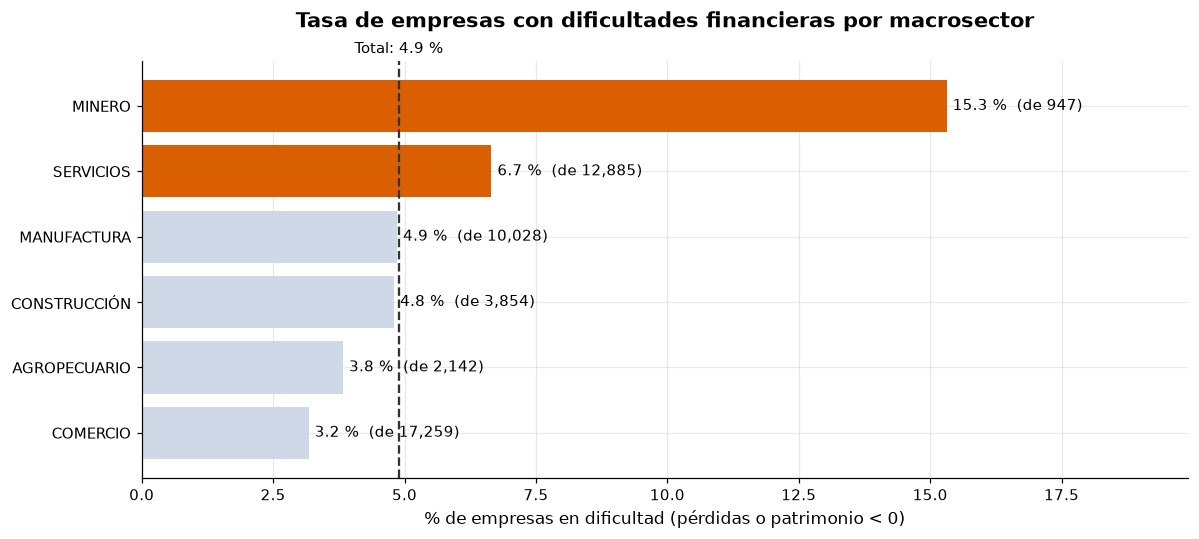

In [4]:
rate_by_sector = (distress.groupby(df["macrosector"]).mean() * 100).sort_values()
sector_counts = df["macrosector"].value_counts()
overall_rate = distress.mean() * 100

fig, ax = plt.subplots(figsize=(11, 5))
estilo.labeled_barh(
    ax, rate_by_sector,
    labels=[f"{r:.1f} %  (de {sector_counts[s]:,})" for s, r in rate_by_sector.items()],
    # Naranja si el sector está por encima de la tasa de todo el ranking
    colors=estilo.highlight_above(rate_by_sector, overall_rate),
)
ax.axvline(overall_rate, color=estilo.DARK, linestyle="--", linewidth=1.5)
ax.text(
    overall_rate, 1.01, f"Total: {overall_rate:.1f} %", transform=ax.get_xaxis_transform(),
    ha="center", va="bottom", fontsize=10,
)
ax.set_title("Tasa de empresas con dificultades financieras por macrosector", pad=22)
ax.set_xlabel("% de empresas en dificultad (pérdidas o patrimonio < 0)")
plt.tight_layout()
estilo.save_figure(fig, "fig03_dificultad_por_macrosector.png")
plt.show()

## P4 · ¿Cambia la tasa de dificultad con el ciclo económico?

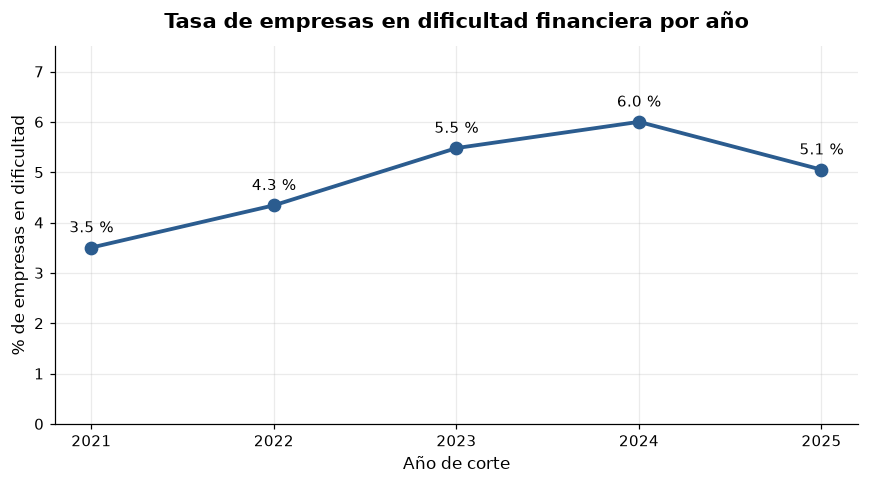

In [5]:
rate_by_year = distress.groupby(df["year"]).mean() * 100

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(rate_by_year.index, rate_by_year.values, marker="o", color=estilo.MAIN, linewidth=2.5, markersize=8)
for year, rate in rate_by_year.items():
    ax.annotate(f"{rate:.1f} %", (year, rate), textcoords="offset points", xytext=(0, 10), ha="center", fontsize=10)
ax.set_title("Tasa de empresas en dificultad financiera por año")
ax.set_xlabel("Año de corte")
ax.set_ylabel("% de empresas en dificultad")
ax.set_xticks(rate_by_year.index)
ax.set_ylim(0, rate_by_year.max() * 1.25)
plt.tight_layout()
estilo.save_figure(fig, "fig04_dificultad_por_anio.png")
plt.show()

## P5 · ¿Qué tan redundantes son las variables financieras?

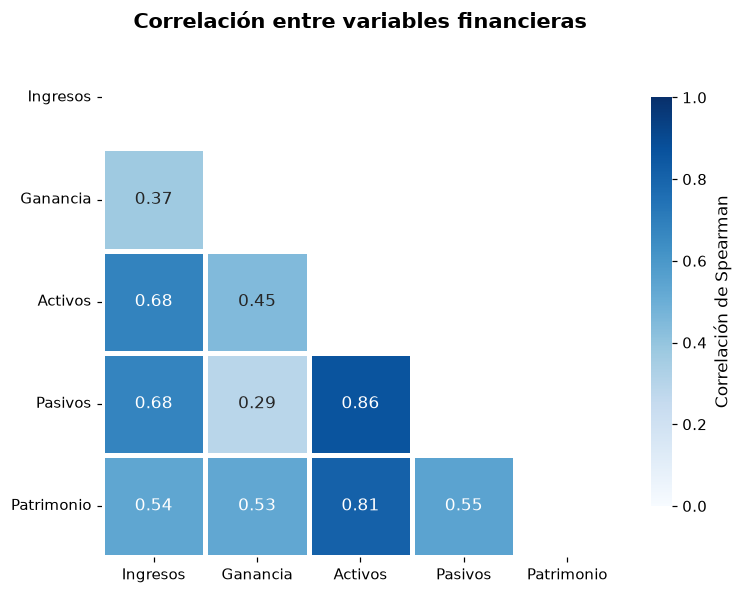

In [6]:
# Spearman: robusta a la fuerte asimetría (se muestra solo el triángulo inferior)
corr = df[utils.FINANCIAL_COLS].corr(method="spearman")
corr.index = corr.columns = ["Ingresos", "Ganancia", "Activos", "Pasivos", "Patrimonio"]

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(
    corr, mask=np.triu(np.ones_like(corr, dtype=bool)), annot=True, fmt=".2f",
    cmap=estilo.CMAP, vmin=0, vmax=1, annot_kws={"fontsize": 11}, linewidths=2, linecolor="white",
    cbar_kws={"label": "Correlación de Spearman", "shrink": 0.8}, ax=ax,
)
ax.grid(False)
ax.tick_params(axis="y", rotation=0)
ax.set_title("Correlación entre variables financieras")
plt.tight_layout()
estilo.save_figure(fig, "fig05_correlacion_variables_financieras.png")
plt.show()

## Cifras clave que cita el informe

In [7]:
# Concentración: cuánto de los ingresos de cada año se lleva el Top 100
revenue_by_year = df.groupby("year")["operating_revenue"]
pareto = pd.DataFrame({
    "Ingresos totales (billones)": revenue_by_year.sum(),
    "Ingresos Top 100 (billones)": revenue_by_year.apply(lambda s: s.nlargest(100).sum()),
})
pareto["% del Top 100"] = pareto["Ingresos Top 100 (billones)"] / pareto["Ingresos totales (billones)"] * 100
pareto.round(1)

,Ingresos totales (billones),Ingresos Top 100 (billones),% del Top 100
year,,,
2021,1164.1,431.2,37.0
2022,1576.6,619.4,39.3
2023,1735.8,649.3,37.4
2024,1733.5,613.9,35.4
2025,1852.8,615.3,33.2


In [8]:
# Rotación: empresas que aparecen los 5 años del ranking
years_present = df.groupby("nit")["year"].nunique()
print(f"Empresas presentes los 5 años: {(years_present == 5).mean():.1%}")

Empresas presentes los 5 años: 42.3%
